# Pricing 15-minute Bitcoin moves: fat tails, GARCH, and Kalshi

Kalshi lists a market every 15 minutes: *will BTC be higher at the end of this window than at the start?* That's a short-dated digital option on Bitcoin. To price one you need the probability that BTC's 15-minute return clears a threshold, and that depends almost entirely on how you model volatility and the tails.

The Black-Scholes answer is a normal distribution with constant volatility. This notebook checks how wrong that is for BTC and what fixes it:

1. How far are real 15-minute BTC returns from normal? (Section 2)
2. Do models that use historical returns or recent volatility give better probabilities on a month they've never seen? This compares the empirical distribution, a logistic regression, a small neural net, and EWMA and GARCH(1,1) with normal and Student-t shocks. (Sections 4–6)
3. Are any of them better than Kalshi's own prices, and can any of it be traded profitably? (Sections 7–8)

**Data.** Every 1-minute BTCUSDT candle on Binance from May 1 to October 31, 2026 (264,960 minutes), plus Kalshi's public KXBTC15M market data for September and October. Models are fit on May–August, choices are made on September, and October is touched once at the end.

**Sections**
1. Raw prices to 15-minute returns, with data checks
2. Real returns vs. a normal distribution
3. Setting up the prediction test
4. Normal vs. empirical distribution
5. Logistic regression and a neural net using recent volatility
6. EWMA and GARCH(1,1), priced as Black-Scholes digitals
7. Comparing against Kalshi's prices
8. Four trading strategies
9. Summary

Code is in `btc_tails/` (download, SQL, features, models, volatility models, scoring, strategies), and tests are in `tests/`.

In [1]:
import json, sqlite3, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))
from btc_tails import DB_PATH, RAW_KALSHI, SQL_DIR, VENUE, PAIR, MONTHS
from btc_tails.build_db import read_sql_blocks
from btc_tails.features import (STRIKES_BPS, BPS, load_windows, load_minutes, trailing_features,
                                stack_strikes, chronological_split, event_threshold)
from btc_tails.models import NormalModel, EmpiricalModel, logistic_design, logistic_pipeline, net_inputs, fit_gaussian_net
from btc_tails.vol import VolModel, seasonal_scale, slot_of
from btc_tails.evaluate import EPS, brier, log_loss, score_table, reliability, monotonicity_violations, block_bootstrap_diff

assert DB_PATH.exists(), "Run `python -m btc_tails.download_binance` and `python -m btc_tails.build_db` first (see README)."
con = sqlite3.connect(DB_PATH)

pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
                     "axes.titlesize": 11.5, "axes.titleweight": "bold", "font.size": 9.5, "lines.linewidth": 2})
COLORS = {"normal": "#257de0", "empirical": "#f47230", "logistic": "#00b894", "torch": "#f2a600", "garch": "#7b5cd6",
          "market": "#ee7fac", "data": "#666666"}
def show(s): display(Markdown(s))
def utc(t): return pd.to_datetime(t, unit="s", utc=True)
def ts(s): return int(pd.Timestamp(s, tz="UTC").timestamp())

T_MIN, T_MAX = ts("2026-05-01"), ts("2026-11-01")   # windows with decision time in [T_MIN, T_MAX)
VAL_START, TEST_START = ts("2026-09-01"), ts("2026-10-01")

## 1. From raw prices to 15-minute moves

Binance gives one price candle per minute. To get a 15-minute move, I take the price right when the window starts and the price right when it ends, and measure the change. The only tricky part is picking the right candles, so I never use a price that wasn't known yet.

**Where the data comes from.** [Binance public data](https://github.com/binance/binance-public-data) has monthly files of 1-minute BTCUSDT candles, and I use May through October 2026. Each file is checked against Binance's published checksum so I know it downloaded intact. A candle's timestamp marks when its minute *starts*. Binance stores it in microseconds, and I convert it to seconds (UTC). So a candle stamped 12:00 covers 12:00:00 to 12:00:59, and its closing price is known at 12:01.

**How a 15-minute move is measured.** Windows start at :00, :15, :30 and :45 UTC. For a window starting at time $T$:
- start price $S$ = closing price of the candle that starts at $T-1$ min (it finishes exactly at $T$)
- end price $S_{end}$ = closing price of the candle that starts at $T+14$ min (it finishes at $T+15$)
- the move is $r = \log(S_{end}/S)$. For moves this small, that's essentially the percentage change.

I report moves in **basis points (bps)**: 1 bp = 0.01%, so 25 bps = 0.25%.

A window only counts if all 16 minutes from $T-1$ to $T+14$ are there. Missing minutes are never filled in. The SQL lives in `btc_tails/sql/`.

**The two tables below** check that there's exactly one candle per minute, with no duplicates and no gaps, and show how many windows survive.

In [2]:
audit = read_sql_blocks("audit.sql")
p = {"venue": VENUE, "pair": PAIR}
counts = pd.read_sql_query(audit["row_counts"], con)
dups = pd.read_sql_query(audit["duplicate_keys"], con)
mis = pd.read_sql_query(audit["misaligned_rows"], con)
gaps = pd.read_sql_query(audit["gaps"], con, params=p)
expected = (T_MAX - T_MIN) // 60
audit_tbl = pd.DataFrame({
    "check": ["raw rows read", "rows kept (one per minute)", "expected minutes in window", "first candle open (UTC)",
              "last candle open (UTC)", "duplicated keys (exact / conflicting)", "rows not on a whole minute", "gaps (count / missing minutes)"],
    "value": [f"{counts.raw_rows[0]:,}", f"{counts.kept_rows[0]:,}", f"{expected:,}", utc(counts.first_ts_open[0]), utc(counts.last_ts_open[0]),
              f"{int(dups.duplicated_keys[0])} ({int(dups.exact_duplicate_keys[0] or 0)} / {int(dups.conflicting_keys[0] or 0)})",
              int(mis.misaligned_rows[0]), f"{len(gaps)} / {int(gaps.missing_minutes.sum()) if len(gaps) else 0}"]})
audit_tbl

,check,value
0,raw rows read,"264,960"
1,rows kept (one per minute),"264,960"
2,expected minutes in window,"264,960"
3,first candle open (UTC),2026-05-01 00:00:00+00:00
4,last candle open (UTC),2026-10-31 23:59:00+00:00
5,duplicated keys (exact / conflicting),0 (0 / 0)
6,rows not on a whole minute,0
7,gaps (count / missing minutes),0 / 0


In [3]:
w = load_windows(T_MIN, T_MAX, con)
feats = trailing_features(load_minutes(con), w["t_decision"].to_numpy())
w = w.merge(feats, on="t_decision")
FEATS = ["rv_60", "rv_240", "r_lag1", "r_lag2"]
n_cal = len(w)
bad_window = w["is_valid"] == 0
bad_feat = ~bad_window & w[FEATS].isna().any(axis=1)
drop_tbl = pd.DataFrame({
    "step": ["calendar windows 2026-05-01 00:00 to 2026-10-31 23:45 UTC",
             "dropped: a needed candle is missing (incl. the first window, whose start candle is 2026-04-30 23:59)",
             "dropped: trailing features incomplete (needs 4h of history before the first window)",
             "kept for all analysis"],
    "windows": [n_cal, int(bad_window.sum()), int(bad_feat.sum()), int((~bad_window & ~bad_feat).sum())]})
df = w.loc[~bad_window & ~bad_feat].reset_index(drop=True)
df["r_bps"] = df["r"] * BPS
drop_tbl

,step,windows
0,calendar windows 2026-05-01 00:00 to 2026-10-3...,17664
1,dropped: a needed candle is missing (incl. the...,1
2,dropped: trailing features incomplete (needs 4...,16
3,kept for all analysis,17647


Here are three real windows pulled straight from the database, so you can check by hand that the right candles are being used:

In [4]:
q = "SELECT ts_open, close FROM candles WHERE venue=? AND pair=? AND ts_open=?"
rows = []
for T in df["t_decision"].iloc[[0, len(df) // 2, -1]]:
    s0 = con.execute(q, (VENUE, PAIR, int(T - 60))).fetchone()
    s1 = con.execute(q, (VENUE, PAIR, int(T + 840))).fetchone()
    rows.append({"decision time T (UTC)": utc(T), "start candle opens": utc(s0[0]), "S = its close": s0[1],
                 "end candle opens": utc(s1[0]), "S_end = its close": s1[1],
                 "r = log(S_end/S), bps": round(np.log(s1[1] / s0[1]) * BPS, 3)})
pd.DataFrame(rows)

,decision time T (UTC),start candle opens,S = its close,end candle opens,S_end = its close,"r = log(S_end/S), bps"
0,2026-05-01 04:15:00+00:00,2026-05-01 04:14:00+00:00,77116.28,2026-05-01 04:29:00+00:00,77012.35,-13.486
1,2026-08-01 02:00:00+00:00,2026-08-01 01:59:00+00:00,62975.01,2026-08-01 02:14:00+00:00,63018.00,6.824
2,2026-10-31 23:45:00+00:00,2026-10-31 23:44:00+00:00,77523.86,2026-10-31 23:59:00+00:00,77582.02,7.499


## 2. How different are real moves from a bell curve?

If BTC's 15-minute moves followed a bell curve, most moves would be small, big moves would be extremely rare, and up and down would mirror each other. I check that four ways: summary numbers, a histogram, a Q–Q plot, and plain counts of how often big moves happened.

**How to read the summary numbers**
- **std dev:** the typical size of a move.
- **skewness:** whether one side is bigger. Positive means big up-moves outweigh big down-moves. A bell curve has 0.
- **excess kurtosis:** how often extreme moves show up compared with a bell curve. A bell curve has 0, and higher means more extreme moves.

One guess going in was that the skew is positive, meaning big up-moves outweigh big down-moves.

*(Technical details: variance uses $n-1$. Skewness and kurtosis are scipy's bias-corrected versions, `bias=False`.)*

In [5]:
r = df["r_bps"].to_numpy()
mom = pd.Series({"n (windows)": len(r), "mean (bps)": r.mean(), "variance (bps^2)": r.var(ddof=1),
                 "std dev (bps)": r.std(ddof=1), "skewness": stats.skew(r, bias=False),
                 "excess kurtosis": stats.kurtosis(r, bias=False)}).round(3).to_frame("all six months")
mom

,all six months
n (windows),17647.000
mean (bps),0.003
variance (bps^2),395.353
std dev (bps),19.883
skewness,0.160
excess kurtosis,16.948


**Histogram.** The grey bars are real moves. The blue line is the bell curve fitted to the same data. Look for a middle that's taller and narrower than the curve, and for bars poking out past the curve at the edges.

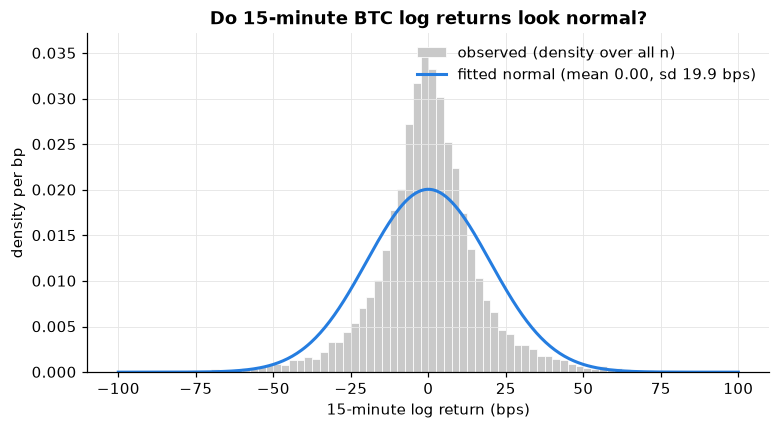

*BTCUSDT, 2026-05-01 to 2026-10-31, n = 17,647 windows. Visible range ±100 bps; 61 observations (0.35%) lie outside it and are included in the density scaling.*

In [6]:
mu, sd = r.mean(), r.std(ddof=1)
lim = 100
fig, ax = plt.subplots(figsize=(8, 4))
inside = r[np.abs(r) <= lim]
bw = 2.5   # bin width in bps; heights = count / (n_all * bw), so the area over the visible range is the share inside it
ax.hist(inside, bins=np.arange(-lim, lim + bw, bw), color="#c9c9c9", edgecolor="white", linewidth=0.5,
        label="observed (density over all n)", weights=np.full(len(inside), 1 / (len(r) * bw)))
x = np.linspace(-lim, lim, 400)
ax.plot(x, stats.norm.pdf(x, mu, sd), color=COLORS["normal"], label=f"fitted normal (mean {mu:.2f}, sd {sd:.1f} bps)")
n_out = int((np.abs(r) > lim).sum())
ax.set(xlabel="15-minute log return (bps)", ylabel="density per bp",
       title="Do 15-minute BTC log returns look normal?")
ax.legend(frameon=False)
plt.show()
show(f"*BTCUSDT, {utc(df.t_decision.min()):%Y-%m-%d} to {utc(df.t_decision.max()):%Y-%m-%d}, n = {len(r):,} windows. "
     f"Visible range ±{lim} bps; {n_out} observations ({n_out/len(r):.2%}) lie outside it and are included in the density scaling.*")

**Q–Q plot.** Each dot pairs a real move with where a bell curve says it should fall. If BTC were bell-shaped, the dots would sit on the straight line. Dots bending away at the ends mean the extremes are more extreme than a bell curve allows.

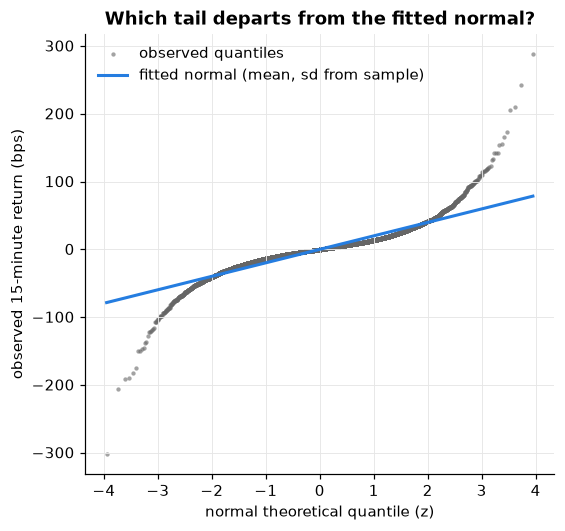

*At z = −3 the sample quantile is -102.7 bps vs -59.6 bps under the fit; at z = +3 it is 110.3 vs 59.7 bps. Most extreme: -302 bps and +289 bps.*

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5.2))
(osm, osr), _ = stats.probplot(r, dist="norm")
ax.scatter(osm, osr, s=8, color=COLORS["data"], alpha=0.6, linewidths=0, label="observed quantiles")
ax.plot(osm, mu + sd * osm, color=COLORS["normal"], label="fitted normal (mean, sd from sample)")
ax.set(xlabel="normal theoretical quantile (z)", ylabel="observed 15-minute return (bps)",
       title="Which tail departs from the fitted normal?")
ax.legend(frameon=False, loc="upper left")
plt.show()
z = np.array([-3, 3]); qq = np.quantile(r, stats.norm.cdf(z))
show(f"*At z = −3 the sample quantile is {qq[0]:.1f} bps vs {mu+sd*z[0]:.1f} bps under the fit; at z = +3 it is {qq[1]:.1f} vs {mu+sd*z[1]:.1f} bps. "
     f"Most extreme: {r.min():.0f} bps and +{r.max():.0f} bps.*")

**Counting big moves.** For each size threshold: how many windows actually moved more than that, and how many a bell curve expects. This is the most direct way to see the tails.

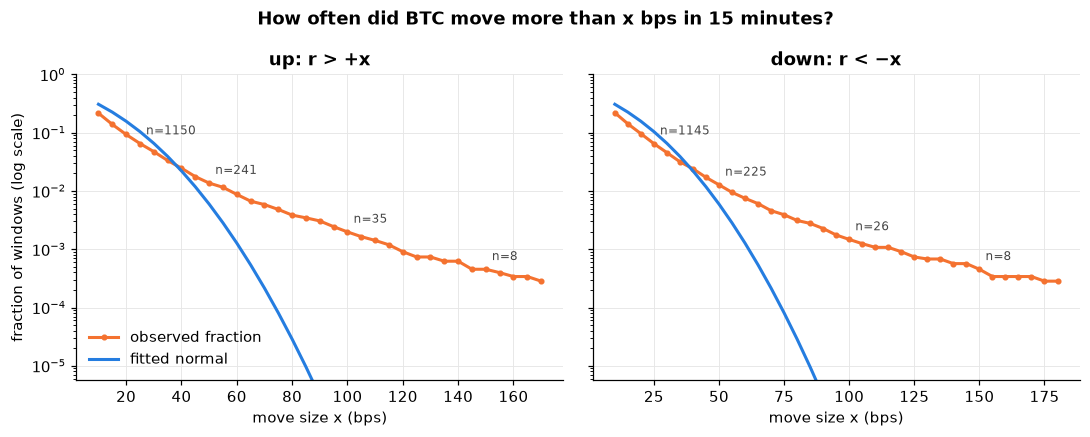

*Only thresholds with at least 5 observed windows are drawn (n = 17,647). Labels show the raw window counts. The y-axis stops at 0.1/n; below that the normal curve continues off the chart.*

In [8]:
thr = np.arange(10, 201, 5)
up = np.array([(r > t).sum() for t in thr]); dn = np.array([(r < -t).sum() for t in thr])
keep = (up >= 5) | (dn >= 5)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, cnt, side, sign in [(axes[0], up, "up", 1), (axes[1], dn, "down", -1)]:
    m = cnt >= 5
    ax.plot(thr[m], cnt[m] / len(r), color=COLORS["empirical"], marker="o", ms=3, label="observed fraction")
    normp = stats.norm.sf(thr, mu, sd) if sign > 0 else stats.norm.cdf(-thr, mu, sd)
    ax.plot(thr[m], normp[m], color=COLORS["normal"], label="fitted normal")
    for t in (25, 50, 100, 150):
        i = np.where(thr == t)[0][0]
        if m[i]: ax.annotate(f"n={cnt[i]}", (t, cnt[i] / len(r)), textcoords="offset points", xytext=(4, 6), fontsize=8, color="#444")
    ax.set_yscale("log"); ax.set_ylim(0.1 / len(r), 1); ax.set_xlabel(f"move size x (bps)")
    ax.set_title(f"{side}: r {'> +x' if sign>0 else '< −x'}")
axes[0].set_ylabel("fraction of windows (log scale)"); axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("How often did BTC move more than x bps in 15 minutes?", fontweight="bold", fontsize=11.5)
plt.tight_layout(); plt.show()
show(f"*Only thresholds with at least 5 observed windows are drawn (n = {len(r):,}). Labels show the raw window counts. The y-axis stops at 0.1/n; below that the normal curve continues off the chart.*")

In [9]:
rows = []
for t in (25, 50, 75, 100, 150):
    rows.append({"x (bps)": t, "observed r > +x": int((r > t).sum()), "normal expects": round(len(r) * stats.norm.sf(t, mu, sd), 1),
                 "observed r < −x": int((r < -t).sum()), "normal expects ": round(len(r) * stats.norm.cdf(-t, mu, sd), 1)})
tail_tbl = pd.DataFrame(rows); tail_tbl

,x (bps),observed r > +x,normal expects,observed r < −x,normal expects
0,25,1150,1841.4,1145,1840.4
1,50,241,105.2,225,105.1
2,75,85,1.4,69,1.4
3,100,35,0.0,26,0.0
4,150,8,0.0,8,0.0


**Reading the table above.** Moves past ±25 bps (0.25%) happened 2,295 times, while a bell curve expects about 3,682. Moves past ±50 bps happened 466 times against about 210 expected, and moves past ±75 bps happened 154 times against about 3.

**Is the lean real, or just a few wild windows?** A single huge move can swing the skewness number a lot. So below I recompute the numbers month by month and list the most extreme windows. The last table is only a **what-if**: it drops the 5 biggest moves to see how much the result depends on them. Everything else in the notebook uses all the data.

In [10]:
df["month"] = utc(df.t_decision).dt.strftime("%Y-%m")
sub = df.groupby("month")["r_bps"].agg(n="size", std_bps=lambda x: x.std(ddof=1),
                                         skew=lambda x: stats.skew(x, bias=False), excess_kurt=lambda x: stats.kurtosis(x, bias=False)).round(2)
display(sub)
ext = df.reindex(df["r_bps"].abs().sort_values(ascending=False).index).head(8)
display(pd.DataFrame({"window start (UTC)": utc(ext.t_decision), "S": ext.s_start, "S_end": ext.s_end, "r (bps)": ext.r_bps.round(1)}).reset_index(drop=True))
top5 = df["r_bps"].abs().nlargest(5).index
r_ex = df.drop(top5)["r_bps"]
sens = pd.DataFrame({"skewness": [stats.skew(r, bias=False), stats.skew(r_ex, bias=False)],
                     "excess kurtosis": [stats.kurtosis(r, bias=False), stats.kurtosis(r_ex, bias=False)]},
                    index=["all windows", "SENSITIVITY: without 5 largest |r|"]).round(3)
sens

,n,std_bps,skew,excess_kurt
month,,,,
2026-05,2959,16.28,-0.13,9.31
2026-06,2880,28.24,-0.04,12.45
2026-07,2976,17.65,0.28,5.37
2026-08,2976,19.10,1.54,25.33
2026-09,2880,18.77,-0.06,14.63
2026-10,2976,17.06,-0.41,13.63


,window start (UTC),S,S_end,r (bps)
0,2026-06-25 13:45:00+00:00,60077.99,58290.17,-302.1
1,2026-06-07 22:00:00+00:00,61778.41,63586.98,288.5
2,2026-08-19 15:15:00+00:00,66654.00,68291.89,242.8
3,2026-08-20 08:00:00+00:00,69816.45,71300.01,210.3
4,2026-09-04 12:30:00+00:00,81340.00,79686.00,-205.4
5,2026-08-21 08:45:00+00:00,77647.34,79258.03,205.3
6,2026-06-25 13:30:00+00:00,61240.01,60077.99,-191.6
7,2026-10-29 20:30:00+00:00,80395.81,78884.52,-189.8


,skewness,excess kurtosis
all windows,0.160,16.948
SENSITIVITY: without 5 largest |r|,0.086,9.956


In [11]:
lo, hi = sub["skew"].idxmin(), sub["skew"].idxmax()
show(f"Monthly skew ranges from {sub.loc[lo,'skew']:.2f} ({lo}) to {sub.loc[hi,'skew']:.2f} ({hi}). Full-sample skew is "
     f"{stats.skew(r, bias=False):.3f}; without the 5 largest moves it is {stats.skew(r_ex, bias=False):.3f}. "
     f"Excess kurtosis is positive in every month (min {sub['excess_kurt'].min():.1f}).")

Monthly skew ranges from -0.41 (2026-10) to 1.54 (2026-08). Full-sample skew is 0.160; without the 5 largest moves it is 0.086. Excess kurtosis is positive in every month (min 5.4).

## 3. Setting up the prediction test

"Will BTC finish above price $K$?" is the same question as "will BTC move by at least a certain amount?" So every model only has to answer one thing: how likely is the next 15-minute move to be bigger than some amount $m$? Then I test each model on a month it never saw.

**Turning a price level into a required move.** At time $T$, BTC is at $S$. It finishes above $K$ exactly when $S_{end} > K$, which is the same as $r > \log(K/S)$. I call $m = \log(K/S)$ the *required move*. This part always uses strict ">".

**Strikes.** For each window I make up five price levels: 50 bps below the current price, 25 below, right at it, 25 above, and 50 above. In symbols, $k \in \{-50,-25,0,+25,+50\}$ bps and $K = S\,e^{k/10^4}$, so $m = k/10^4$ exactly. These levels are hypothetical. Section 7 uses Kalshi's real ones.

**What the volatility-aware models get to see.** Everything here is known at time $T$ and uses only finished candles.
- `rv_60` and `rv_240`: how jumpy BTC was over the last 1 hour and the last 4 hours (realized volatility, scaled to a 15-minute size).
- `r_lag1` and `r_lag2`: the moves in the previous two 15-minute windows.

All of these only look backward, and they require every minute to be present.

**Train, validate, test.** The data is split by date and never shuffled. Models learn from May through August, I make setup choices on September, and October is the final test. All five strikes from a window stay in the same group. Any row whose outcome lands after the next group starts would be dropped, but none needed to be.

The second table below lists exactly which candles feed the inputs for the first test window, so you can check that nothing peeks ahead.

In [12]:
df, n_purged = chronological_split(df, VAL_START, TEST_START)
split_tbl = df.groupby("split").agg(first_T=("t_decision", "min"), last_T=("t_decision", "max"), windows=("t_decision", "size"))
split_tbl = split_tbl.loc[["train", "val", "test"]]
split_tbl["last label resolves"] = utc(split_tbl.last_T + 900)
split_tbl["first_T"], split_tbl["last_T"] = utc(split_tbl.first_T), utc(split_tbl.last_T)
split_tbl["rows (x5 strikes)"] = split_tbl.windows * len(STRIKES_BPS)
assert (df.loc[df.split == "train", "t_decision"] + 900 <= VAL_START).all()
assert (df.loc[df.split == "val", "t_decision"] + 900 <= TEST_START).all()
display(split_tbl)
show(f"Purged for label overlap: {n_purged} (windows are aligned to whole days, so none overlap).")

,first_T,last_T,windows,last label resolves,rows (x5 strikes)
split,,,,,
train,2026-05-01 04:15:00+00:00,2026-08-31 23:45:00+00:00,11791,2026-09-01 00:00:00+00:00,58955
val,2026-09-01 00:00:00+00:00,2026-09-30 23:45:00+00:00,2880,2026-10-01 00:00:00+00:00,14400
test,2026-10-01 00:00:00+00:00,2026-10-31 23:45:00+00:00,2976,2026-11-01 00:00:00+00:00,14880


Purged for label overlap: 0 (windows are aligned to whole days, so none overlap).

In [13]:
row = df[df.split == "test"].iloc[0]
T = int(row.t_decision)
pd.DataFrame({
  "item": ["decision time T", "rv_60 uses candles opening", "rv_240 uses candles opening", "r_lag1 uses closes of candles opening",
           "r_lag2 uses closes of candles opening", "latest input known at", "label uses close of candle opening (known at)"],
  "UTC": [utc(T), f"{utc(T-60*60)} .. {utc(T-60)}", f"{utc(T-240*60)} .. {utc(T-60)}", f"{utc(T-960)} and {utc(T-60)}",
          f"{utc(T-1860)} and {utc(T-960)}", utc(row.feature_known_at), f"{utc(T+840)} ({utc(T+900)})"]})

,item,UTC
0,decision time T,2026-10-01 00:00:00+00:00
1,rv_60 uses candles opening,2026-09-30 23:00:00+00:00 .. 2026-09-30 23:59:...
2,rv_240 uses candles opening,2026-09-30 20:00:00+00:00 .. 2026-09-30 23:59:...
3,r_lag1 uses closes of candles opening,2026-09-30 23:44:00+00:00 and 2026-09-30 23:59...
4,r_lag2 uses closes of candles opening,2026-09-30 23:29:00+00:00 and 2026-09-30 23:44...
5,latest input known at,2026-10-01 00:00:00+00:00
6,label uses close of candle opening (known at),2026-10-01 00:14:00+00:00 (2026-10-01 00:15:00...


## 4. Bell curve vs. "just count"

I start with two simple ways to estimate the chance of a move bigger than $m$:
- **A. Bell curve (normal):** fit a bell curve to the training moves and read off the probability, $P(r>m) = 1-\Phi((m-\hat\mu)/\hat\sigma)$.
- **B. Just count (empirical):** the fraction of training windows that moved more than $m$.

Both learn from May through August only. Neither looks at recent volatility, so each gives the same answer for every window at a given strike.

**How the models are scored** (lower is better for both):
- **Brier score:** the average squared gap between the predicted probability and what happened (1 or 0).
- **Log loss:** like Brier, but it punishes confident wrong answers much harder. This is my main score.

Before computing log loss, I clip every probability to between 0.0001 and 0.9999. That way a model that says "0%" and turns out wrong gets a big penalty (about 9.2) instead of an infinite one. The Brier score uses the unclipped probabilities.

First, here's one real October example that shows where the two models disagree and why.

In [14]:
tr_r = df.loc[df.split == "train", "r"].to_numpy()
normal, emp = NormalModel().fit(tr_r), EmpiricalModel().fit(tr_r)
S = stack_strikes(df)
S["m"] = S["k_bps"] / BPS
S["normal"] = normal.prob_above(S["m"])
S["empirical"] = emp.prob_above(S["m"])
S["day"] = utc(S.t_decision).dt.date
strike_tbl = pd.DataFrame({"strike k (log bps)": STRIKES_BPS,
                           "P normal": normal.prob_above(np.array(STRIKES_BPS) / BPS),
                           "P empirical": emp.prob_above(np.array(STRIKES_BPS) / BPS),
                           "training windows with r > k": emp.count_above(np.array(STRIKES_BPS) / BPS)})
strike_tbl["difference (emp − normal)"] = strike_tbl["P empirical"] - strike_tbl["P normal"]
show(f"Training fit: mean = {normal.mu*BPS:.3f} bps, sd = {normal.sigma*BPS:.2f} bps, n = {normal.n:,} windows.")
strike_tbl.round(4)

Training fit: mean = 0.016 bps, sd = 20.79 bps, n = 11,791 windows.

,strike k (log bps),P normal,P empirical,training windows with r > k,difference (emp − normal)
0,-50,0.9919,0.9858,11624,-0.0061
1,-25,0.8856,0.9306,10973,0.0451
2,0,0.5003,0.4916,5796,-0.0087
3,25,0.1147,0.0706,832,-0.0442
4,50,0.0081,0.0160,189,0.0079


In [15]:
k_star = int(strike_tbl.loc[strike_tbl["difference (emp − normal)"].abs().idxmax(), "strike k (log bps)"])
ex = S[(S.split == "test") & (S.k_bps == k_star)].iloc[0]          # first held-out window, not hand-picked
cnt = int(emp.count_above(k_star / BPS))
pd.DataFrame({"": ["decision time T (UTC)", "expiry (UTC)", "time to expiry", "S (BTCUSDT close at T)", f"strike K = S·exp({k_star}/10⁴)",
                   "required move log(K/S)", "P normal", "P empirical", f"training windows with r > {k_star} bps", "S_end", "realized r", "outcome (S_end > K)"],
              "value": [utc(ex.t_decision), utc(ex.t_label), "15 min", f"{ex.s_start:,.2f}", f"{ex.K:,.2f}", f"{ex.m*BPS:.1f} bps",
                        f"{ex.normal:.4f}", f"{ex.empirical:.4f}", f"{cnt:,} of {emp.n:,}", f"{ex.s_end:,.2f}", f"{ex.r*BPS:.2f} bps", int(ex.y)]})

,,value
0,decision time T (UTC),2026-10-01 00:00:00+00:00
1,expiry (UTC),2026-10-01 00:15:00+00:00
2,time to expiry,15 min
3,S (BTCUSDT close at T),"83,623.60"
4,strike K = S·exp(-25/10⁴),"83,414.80"
5,required move log(K/S),-25.0 bps
6,P normal,0.8856
7,P empirical,0.9306
8,training windows with r > -25 bps,"10,973 of 11,791"
9,S_end,"83,509.05"


In [16]:
z_star = (k_star / BPS - normal.mu) / normal.sigma
show(f"**Why they differ at k = {k_star:+d} bps.** The normal uses one sd ({normal.sigma*BPS:.1f} bps) for the whole distribution. "
     f"That sd is inflated by the rare large moves, so a {abs(k_star)} bp move is only {abs(z_star):.2f} sd away and the normal assigns it "
     f"{strike_tbl.set_index('strike k (log bps)').loc[k_star,'P normal']:.3f}. The empirical model just counts: {cnt:,} of {emp.n:,} training "
     f"windows cleared it ({cnt/emp.n:.3f}). The sample is more peaked than the normal, so moderate moves are rarer than the fit implies. "
     f"Large moves are more common, which is why the sign of the difference flips at ±50 bps (table above).")

**Why they differ at k = -25 bps.** The normal uses one sd (20.8 bps) for the whole distribution. That sd is inflated by the rare large moves, so a 25 bp move is only 1.20 sd away and the normal assigns it 0.886. The empirical model just counts: 10,973 of 11,791 training windows cleared it (0.931). The sample is more peaked than the normal, so moderate moves are rarer than the fit implies. Large moves are more common, which is why the sign of the difference flips at ±50 bps (table above).

**Now the whole test month.** Both models are scored on the same 14,880 rows (2,976 October windows × 5 strikes). The second table breaks the scores down by strike.

In [17]:
TE = S[S.split == "test"].copy()
base = score_table(TE, ["normal", "empirical"]).set_index("model")[["n", "brier", "log_loss"]]
by_k = score_table(TE, ["normal", "empirical"], by="k_bps").pivot(index="group", columns="model", values=["brier", "log_loss"])
by_k.index.name = "strike k"
display(base.round(5)); display(by_k.round(5))

,n,brier,log_loss
model,,,
normal,14880,0.07407,0.24823
empirical,14880,0.07255,0.23992


brier           log_loss         
model    empirical   normal empirical   normal
strike k                                      
-50        0.00967  0.00965   0.05561  0.05499
-25        0.04909  0.05274   0.20538  0.22673
 0         0.24996  0.25000   0.69306  0.69316
 25        0.04596  0.04993   0.19619  0.21936
 50        0.00806  0.00800   0.04936  0.04691

**Could the difference be luck?** I resample October by whole days 2,000 times and see how much the gap between the models moves. Each dot is the gap at one strike, and the line through it is its 95% range. Below zero means "just count" did better. If the whole line stays below zero, the win isn't luck.

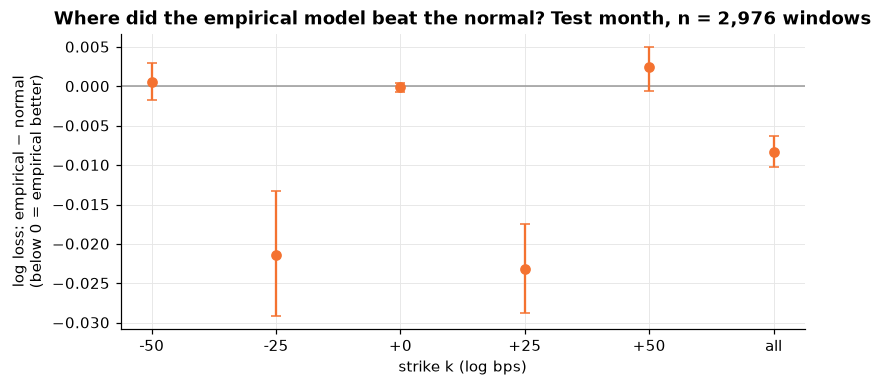

*95% intervals: percentile bootstrap over whole calendar days of the test month (2,000 resamples). All strikes of a window stay together, so five strikes of one realized move are not counted as five independent observations.*

,metric,strike,empirical − normal,95% CI low,95% CI high
0,log_loss,-50,0.00062,-0.00167,0.00291
1,log_loss,-25,-0.02135,-0.02911,-0.01322
2,log_loss,0,-0.00009,-0.00068,0.00048
3,log_loss,25,-0.02317,-0.02874,-0.01742
4,log_loss,50,0.00246,-0.00056,0.00501
5,log_loss,all,-0.00831,-0.01028,-0.00631
6,brier,-50,0.00002,-0.00003,0.00007
7,brier,-25,-0.00365,-0.00492,-0.00232
8,brier,0,-0.00005,-0.00034,0.00024
9,brier,25,-0.00397,-0.00489,-0.00302


In [18]:
rows = []
for metric in ["log_loss", "brier"]:
    for k in STRIKES_BPS + ["all"]:
        d = TE if k == "all" else TE[TE.k_bps == k]
        est, lo_, hi_ = block_bootstrap_diff(d, "empirical", "normal", metric)
        rows.append({"metric": metric, "strike": k, "empirical − normal": est, "95% CI low": lo_, "95% CI high": hi_})
ci = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
c = ci[ci.metric == "log_loss"].reset_index(drop=True)
xs = np.arange(len(c))
ax.axhline(0, color="#999", lw=1)
ax.errorbar(xs, c["empirical − normal"], yerr=[c["empirical − normal"] - c["95% CI low"], c["95% CI high"] - c["empirical − normal"]],
            fmt="o", color=COLORS["empirical"], ms=6, capsize=3, lw=1.5)
ax.set_xticks(xs, [f"{k:+d}" if k != "all" else "all" for k in c.strike])
ax.set(xlabel="strike k (log bps)", ylabel="log loss: empirical − normal\n(below 0 = empirical better)",
       title=f"Where did the empirical model beat the normal? Test month, n = {TE.t_decision.nunique():,} windows")
plt.tight_layout(); plt.show()
show("*95% intervals: percentile bootstrap over whole calendar days of the test month (2,000 resamples). All strikes of a window stay together, "
     "so five strikes of one realized move are not counted as five independent observations.*")
ci.round(5)

In [19]:
a = ci[(ci.metric == "log_loss") & (ci.strike == "all")].iloc[0]
b = ci[(ci.metric == "brier") & (ci.strike == "all")].iloc[0]
show(f"**Result (test, all strikes).** Log loss: normal {base.loc['normal','log_loss']:.4f}, empirical {base.loc['empirical','log_loss']:.4f} "
     f"(difference {a['empirical − normal']:+.4f}, 95% CI [{a['95% CI low']:+.4f}, {a['95% CI high']:+.4f}]). "
     f"Brier: normal {base.loc['normal','brier']:.5f}, empirical {base.loc['empirical','brier']:.5f} "
     f"(difference {b['empirical − normal']:+.5f}, CI [{b['95% CI low']:+.5f}, {b['95% CI high']:+.5f}]).")

**Result (test, all strikes).** Log loss: normal 0.2482, empirical 0.2399 (difference -0.0083, 95% CI [-0.0103, -0.0063]). Brier: normal 0.07407, empirical 0.07255 (difference -0.00152, CI [-0.00190, -0.00112]).

## 5. Does paying attention to recent volatility help?

BTC has calm stretches and wild stretches, and each tends to last a while. Models A and B ignore that. They give the same odds whether the last hour was dead quiet or chaotic. The two models below do pay attention, and each has one specific opponent it has to beat:

- **C. Logistic regression.** A standard, simple model that predicts "did BTC finish above the strike?" from the strike plus the recent-volatility inputs. It's a scikit-learn `Pipeline` that scales the inputs and then fits a logistic regression, with the scaling learned from training data only. I try three versions and keep the one that does best on September. **To count as a win, it has to beat B ("just count") on October**, because B uses the same history without assuming any shape.
- **D. Volatility-aware bell curve.** A small PyTorch neural network takes the 4 recent-volatility inputs and outputs a center and a width for a bell curve. The curve gets wider when things have been wild and narrower when they've been calm. The network has 16 hidden units, learns from the moves themselves, and stops training once September stops improving. **To count as a win, it has to beat A (the plain bell curve) on October.** That tests whether shifting volatility explains part of BTC's extreme moves.

*Disclosure:* In an earlier draft, the network trained with learning rate 0.001 and a cap of 300 rounds, and it hit the cap while still improving (its best round was 298). I saw that run's October scores. Then I raised the cap to 1,000 rounds (stopping after 30 rounds without improvement) and let September choose between learning rates 0.003 and 0.01. Nothing else was changed after I saw October results. The draft's October log loss was 0.2339, and it's 0.2335 now.

In [20]:
TR, VA = S[S.split == "train"], S[S.split == "val"]
sel = []
fits = {}
for spec in ["base", "interaction", "vol_scaled"]:
    Xtr, names = logistic_design(TR, spec); Xva, _ = logistic_design(VA, spec)
    pipe = logistic_pipeline().fit(Xtr, TR.y)
    fits[spec] = (pipe, names)
    pva = pipe.predict_proba(Xva)[:, 1]
    sel.append({"spec": spec, "features": ", ".join(names), "val log loss": log_loss(pva, VA.y), "val Brier": brier(pva, VA.y)})
sel = pd.DataFrame(sel).sort_values("val log loss")
best_spec = sel.iloc[0]["spec"]
display(sel.round(5))
pipe, names = fits[best_spec]
coef = pd.DataFrame({"feature (standardized)": names, "coefficient": pipe.named_steps["logit"].coef_[0]}).round(3)
show(f"Selected on validation: **{best_spec}**. Coefficients are per training-sd of each input:")
coef

,spec,features,val log loss,val Brier
1,interaction,"k, rv_60, rv_240, r_lag1, r_lag2, k_x_rv60",0.24562,0.07611
2,vol_scaled,"k, k_over_rv240, r_lag1, r_lag2",0.24600,0.07617
0,base,"k, rv_60, rv_240, r_lag1, r_lag2",0.25405,0.07688


Selected on validation: **interaction**. Coefficients are per training-sd of each input:

,feature (standardized),coefficient
0,k,-4.678
1,rv_60,0.060
2,rv_240,-0.045
3,r_lag1,-0.037
4,r_lag2,-0.014
5,k_x_rv60,1.213


In [21]:
S["logistic"] = pipe.predict_proba(logistic_design(S, best_spec)[0])[:, 1]

W = df.reset_index(drop=True)
Xw = net_inputs(W)
trm, vam = (W.split == "train").to_numpy(), (W.split == "val").to_numpy()
runs = {lr: fit_gaussian_net(Xw[trm], W.r[trm], Xw[vam], W.r[vam], lr=lr, seed=0) for lr in (3e-3, 1e-2)}
val_nll = {lr: min(h[2] for h in hh) for lr, (_, hh) in runs.items()}
best_lr = min(val_nll, key=val_nll.get)
predict, hist = runs[best_lr]
mu_t, sig_t = predict(Xw)                       # bps
W["mu_t"], W["sig_t"] = mu_t, sig_t
S = S.merge(W[["t_decision", "mu_t", "sig_t"]], on="t_decision", how="left")
S["torch"] = stats.norm.sf((S["k_bps"] - S["mu_t"]) / S["sig_t"])
best_ep = int(np.argmin([h[2] for h in hist]))
te = W.split == "test"
nll_norm = -stats.norm.logpdf(W.r_bps[te], normal.mu * BPS, normal.sigma * BPS).mean()
nll_net = -stats.norm.logpdf(W.r_bps[te], W.mu_t[te], W.sig_t[te]).mean()
show(f"Learning rate chosen on validation NLL: {best_lr} (candidates: " + ", ".join(f"{k}: {v:.4f}" for k, v in val_nll.items()) + "). "
     f"Early stopping kept epoch {best_ep} of {len(hist)} run (validation NLL {hist[best_ep][2]:.4f}). On test returns, mean Gaussian NLL "
     f"(nats per window, returns in bps): constant-σ normal {nll_norm:.4f}, conditional net {nll_net:.4f}. "
     f"Predicted σ on test ranges {W.sig_t[te].min():.1f}–{W.sig_t[te].max():.1f} bps (median {W.sig_t[te].median():.1f}).")

Learning rate chosen on validation NLL: 0.01 (candidates: 0.003: 4.2100, 0.01: 4.2079). Early stopping kept epoch 166 of 197 run (validation NLL 4.2079). On test returns, mean Gaussian NLL (nats per window, returns in bps): constant-σ normal 4.2901, conditional net 4.1132. Predicted σ on test ranges 4.2–29.3 bps (median 15.3).

**All four models on October.** Each model is scored on the same 14,880 rows. The second table runs the luck check on each model's comparison to win. The third is a sanity check: a higher strike should never get a higher probability, and a 0 means no model broke that rule.

In [22]:
MODELS = ["normal", "empirical", "logistic", "torch"]
TE = S[S.split == "test"].copy()
overall = score_table(TE, MODELS).set_index("model")[["n", "brier", "log_loss"]]
earn = []
for model, baseline in [("empirical", "normal"), ("logistic", "empirical"), ("torch", "normal")]:
    for metric in ["log_loss", "brier"]:
        est, l, h = block_bootstrap_diff(TE, model, baseline, metric)
        earn.append({"comparison": f"{model} − {baseline}", "metric": metric, "difference": est, "95% CI low": l, "95% CI high": h,
                     "better on test": model if h < 0 else (baseline if l > 0 else "no clear winner")})
earn = pd.DataFrame(earn)
mono = pd.DataFrame({"model": MODELS, "decision times where P rises with strike": [monotonicity_violations(TE, m) for m in MODELS],
                     "test decision times": TE.t_decision.nunique()})
display(overall.round(5)); display(earn.round(5)); mono

,n,brier,log_loss
model,,,
normal,14880,0.07407,0.24823
empirical,14880,0.07255,0.23992
logistic,14880,0.07182,0.23266
torch,14880,0.07190,0.23351


,comparison,metric,difference,95% CI low,95% CI high,better on test
0,empirical − normal,log_loss,-0.00831,-0.01028,-0.00631,empirical
1,empirical − normal,brier,-0.00152,-0.00190,-0.00112,empirical
2,logistic − empirical,log_loss,-0.00726,-0.00945,-0.00539,logistic
3,logistic − empirical,brier,-0.00073,-0.00112,-0.00045,logistic
4,torch − normal,log_loss,-0.01472,-0.02001,-0.00978,torch
5,torch − normal,brier,-0.00216,-0.00272,-0.00162,torch


,model,decision times where P rises with strike,test decision times
0,normal,0,2976
1,empirical,0,2976
2,logistic,0,2976
3,torch,0,2976


In [23]:
byk = score_table(TE, MODELS, by="k_bps").pivot(index="group", columns="model", values="log_loss")[MODELS]
byk.index.name = "strike k"; byk.columns.name = "log loss"
display(byk.round(4))
best = {m: overall[m].idxmin() for m in ["brier", "log_loss"]}
show(f"Best on test: Brier → **{best['brier']}** ({overall.loc[best['brier'],'brier']:.5f}), "
     f"log loss → **{best['log_loss']}** ({overall.loc[best['log_loss'],'log_loss']:.4f}). "
     f"Spread between best and worst log loss: {overall.log_loss.max()-overall.log_loss.min():.4f} nats per row.")

log loss,normal,empirical,logistic,torch
strike k,,,,
-50,0.0550,0.0556,0.0532,0.0560
-25,0.2267,0.2054,0.1938,0.1934
0,0.6932,0.6931,0.6932,0.6925
25,0.2194,0.1962,0.1806,0.1832
50,0.0469,0.0494,0.0425,0.0423


Best on test: Brier → **logistic** (0.07182), log loss → **logistic** (0.2327). Spread between best and worst log loss: 0.0156 nats per row.

**Calibration plots.** When a model says 30%, does it happen about 30% of the time? Points on the diagonal mean yes.

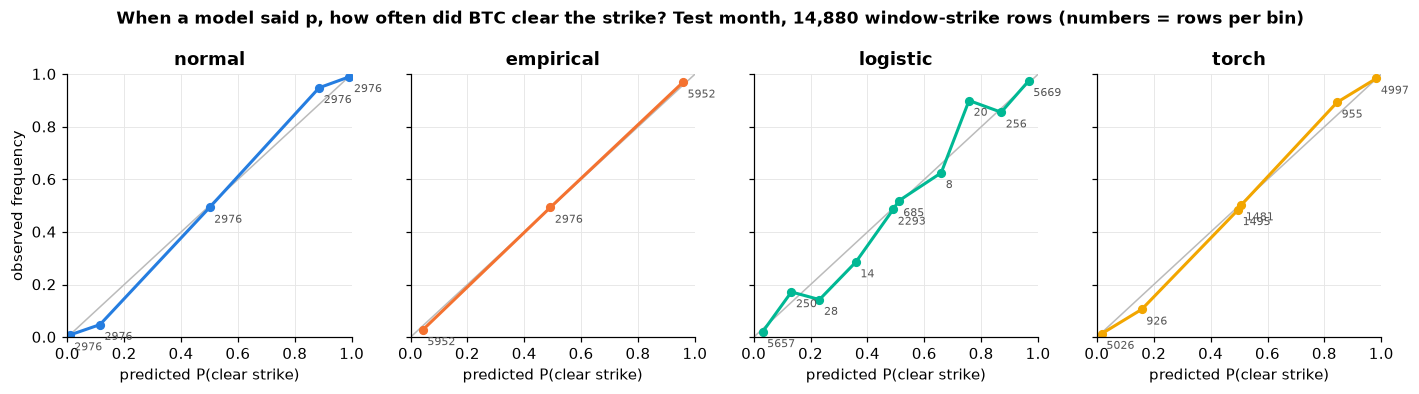

*Unconditional models put every row of a strike in the same bin, so they show at most five points.*

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
for ax, m in zip(axes, MODELS):
    rel = reliability(TE[m], TE.y)
    ax.plot([0, 1], [0, 1], color="#bbb", lw=1)
    ax.plot(rel.mean_pred, rel.obs_freq, marker="o", ms=5, color=COLORS[m])
    for _, rr in rel.iterrows():
        ax.annotate(f"{rr.n}", (rr.mean_pred, rr.obs_freq), textcoords="offset points", xytext=(3, -10), fontsize=7, color="#555")
    ax.set_title(m); ax.set_xlabel("predicted P(clear strike)"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axes[0].set_ylabel("observed frequency")
fig.suptitle(f"When a model said p, how often did BTC clear the strike? Test month, {len(TE):,} window-strike rows (numbers = rows per bin)",
             fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()
show("*Unconditional models put every row of a strike in the same bin, so they show at most five points.*")

### Result table: all four models on October

In [25]:
res = overall.copy()
res["log loss vs normal"] = res.log_loss - res.loc["normal", "log_loss"]
res["Brier vs normal"] = res.brier - res.loc["normal", "brier"]
res["monotonicity violations"] = mono.set_index("model").iloc[:, 0]
res.index.name = f"test {utc(TE.t_decision.min()):%Y-%m-%d}..{utc(TE.t_decision.max()):%Y-%m-%d}"
res.round(5)

,n,brier,log_loss,log loss vs normal,Brier vs normal,monotonicity violations
test 2026-10-01..2026-10-31,,,,,,
normal,14880,0.07407,0.24823,0.00000,0.00000,0
empirical,14880,0.07255,0.23992,-0.00831,-0.00152,0
logistic,14880,0.07182,0.23266,-0.01557,-0.00225,0
torch,14880,0.07190,0.23351,-0.01472,-0.00216,0


## 6. Classic volatility models: EWMA and GARCH

Model D learns how volatility depends on the recent past with a neural net. Before trusting that, it should be compared with the standard tools for exactly this job, which need only 2–4 parameters.

Let $\sigma_t^2$ be the forecast variance of window $t$'s return, using only returns up to $t-1$:

- **EWMA (RiskMetrics):** $\sigma_t^2 = \lambda\,\sigma_{t-1}^2 + (1-\lambda)\,r_{t-1}^2$
- **GARCH(1,1):** $\sigma_t^2 = \omega + \alpha\,r_{t-1}^2 + \beta\,\sigma_{t-1}^2$, stationary when $\alpha+\beta<1$. A shock to variance decays like $(\alpha+\beta)^h$.

Each comes in two versions for the shock $\varepsilon_t = (r_t-\mu)/\sigma_t$:
- **normal**, which is the standard Black-Scholes assumption
- **Student-t** with $\nu$ degrees of freedom (scaled to variance 1), since section 2 showed the tails are much fatter than normal.

**Time of day.** BTC is far more volatile around the US stock market open than in the middle of the Asian night. A GARCH model would read that daily pattern as volatility "shocks". So there's a seasonal option: divide each return by the RMS return for its quarter-hour of the day (fit on May–Aug), run the model on what's left, and multiply back.

**From a volatility forecast to a price.** "Will BTC finish above $K$?" is a cash-or-nothing digital option. Under Black-Scholes with zero rates its value is

$$P(S_T > K) = N(d_2), \qquad d_2 = \frac{\ln(S/K) - \tfrac12\sigma^2\tau}{\sigma\sqrt{\tau}}.$$

Here I plug in the model's $\sigma_t$ for one window ($\tau = 1$). Over 15 minutes the $\tfrac12\sigma^2$ term is about 0.02 bps, so it makes no practical difference. For the Student-t models, $N(\cdot)$ is replaced by the t CDF.

All parameters are fit by maximum likelihood on May–August. The 8 versions (2 models × 2 shock distributions × seasonal or not) are compared on September, and only the winner is scored on October.

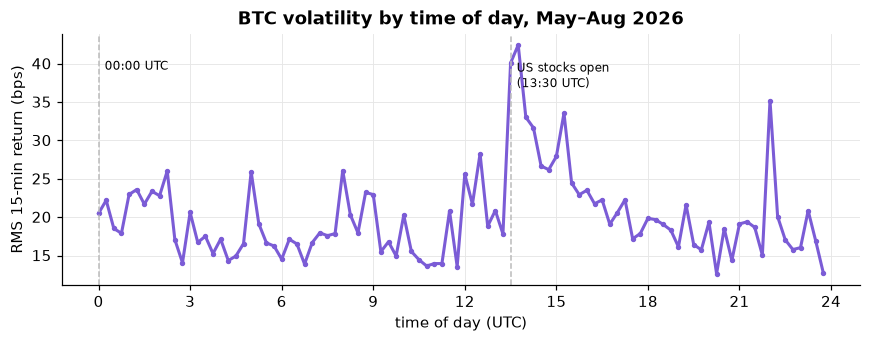

Quietest quarter-hour: 20.25 UTC (0.61× average). Most volatile: 13.75 UTC (2.04× average).

In [26]:
W = W.sort_values("t_decision").reset_index(drop=True)
r_all, t_all = W.r_bps.to_numpy(), W.t_decision.to_numpy()
trm, vam, tem = [(W.split == s).to_numpy() for s in ("train", "val", "test")]

scale = seasonal_scale(r_all[trm] - r_all[trm].mean(), t_all[trm])
hours = np.arange(96) / 4
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(hours, scale * r_all[trm].std(), color=COLORS["garch"], marker="o", ms=2.5)
for h, lab in [(13.5, "US stocks open\n(13:30 UTC)"), (0, "00:00 UTC")]:
    ax.axvline(h, color="#bbb", lw=1, ls="--"); ax.text(h + 0.2, ax.get_ylim()[1] * 0.92, lab, fontsize=8, va="top")
ax.set(xlabel="time of day (UTC)", ylabel="RMS 15-min return (bps)", xticks=range(0, 25, 3),
       title="BTC volatility by time of day, May–Aug 2026")
plt.tight_layout(); plt.show()
show(f"Quietest quarter-hour: {hours[scale.argmin()]:.2f} UTC ({scale.min():.2f}× average). "
     f"Most volatile: {hours[scale.argmax()]:.2f} UTC ({scale.max():.2f}× average).")

In [27]:
def strike_probs(model, sigma, mask):
    P = np.concatenate([model.prob_above(k, sigma[mask]) for k in STRIKES_BPS])
    Y = np.concatenate([(r_all[mask] > k).astype(int) for k in STRIKES_BPS])
    return P, Y

const_sd = r_all[trm].std(ddof=1)
rows, vol_fits = [], {}
for kind in ("ewma", "garch"):
    for dist in ("normal", "t"):
        for seasonal in (False, True):
            m = VolModel(kind, dist, seasonal).fit(r_all[trm], t_all[trm])
            sig = m.sigma(r_all, t_all)
            vol_fits[m.name] = (m, sig)
            P, Y = strike_probs(m, sig, vam)
            persistence = m.params["lam"] if kind == "ewma" else m.params["alpha"] + m.params["beta"]
            rows.append({"model": m.name,
                         "params": ", ".join(f"{k}={v:.3g}" for k, v in m.params.items()),
                         "persistence": persistence, "half-life (hours)": m.half_life() / 4,
                         "train NLL": m.nll(r_all[trm], sig[trm]), "Sep NLL": m.nll(r_all[vam], sig[vam]),
                         "Sep log loss (strikes)": log_loss(P, Y)})
vol_tbl = pd.DataFrame(rows).set_index("model")
base_nll = -stats.norm.logpdf(r_all[vam], r_all[trm].mean(), const_sd).mean()
best_vol = vol_tbl["Sep NLL"].idxmin()
display(vol_tbl.round(4))
show(f"Constant-σ normal (model A) on September: NLL {base_nll:.4f}. NLL is in nats per window with returns in bps, "
     f"computed on the raw returns for every model so the numbers are comparable. **Chosen on September: `{best_vol}`.**")

,params,persistence,half-life (hours),train NLL,Sep NLL,Sep log loss (strikes)
model,,,,,,
ewma-normal,lam=0.942,0.9421,2.9069,4.3009,4.3022,0.2534
ewma-normal-seasonal,lam=0.95,0.9495,3.3466,4.2345,4.2262,0.2499
ewma-t,"lam=0.914, nu=4.53",0.9141,1.9284,4.1803,4.1451,0.2477
ewma-t-seasonal,"lam=0.937, nu=5",0.9372,2.6728,4.1637,4.1320,0.2457
garch-normal,"omega=8.29, alpha=0.147, beta=0.85",0.9968,54.1296,4.2780,4.2682,0.2495
garch-normal-seasonal,"omega=1.92, alpha=0.0689, beta=0.931",0.9999,1732.7813,4.2262,4.2084,0.2491
garch-t,"omega=5.04, alpha=0.146, beta=0.854, nu=4.16",0.9999,1732.7813,4.1730,4.1311,0.2459
garch-t-seasonal,"omega=1.92, alpha=0.0827, beta=0.917, nu=4.55",0.9999,1732.7813,4.1607,4.1253,0.2451


Constant-σ normal (model A) on September: NLL 4.3608. NLL is in nats per window with returns in bps, computed on the raw returns for every model so the numbers are comparable. **Chosen on September: `garch-t-seasonal`.**

**Reading the fits.**
- **Every volatility model beats the constant-σ bell curve on September.** Volatility clusters, so yesterday's calm or chaos tells you something about the next 15 minutes.
- **Student-t beats normal every time, by more than anything else in the table.** The fitted $\nu$ is about 4–5, which is very fat-tailed (a t distribution with $\nu \le 4$ doesn't even have a finite kurtosis). So even after allowing volatility to change over time, the leftover shocks are still far from normal. Volatility clustering explains *some* of the fat tails from section 2, not all of them.
- **Removing the time-of-day pattern helps every model.**
- **GARCH persistence $\alpha+\beta$ ends up at the 0.9999 upper bound I allow.** I checked this by fixing the persistence at values from 0.95 up to 0.99999 and refitting the rest. The likelihood keeps rising all the way to 1, so this is what the data says, not an optimizer failure. It means shocks to volatility barely fade over these four months (an "integrated" GARCH). That's common for intraday data, where the overall volatility level drifts from month to month. It also explains why EWMA, which is the special case $\omega = 0$, $\alpha+\beta = 1$, does almost as well as GARCH.

In [28]:
gm, g_sig = vol_fits[best_vol]
gn, gn_sig = vol_fits["garch-normal"]
G = pd.DataFrame({"t_decision": t_all, "sig_g": g_sig, "sig_gn": gn_sig})
S = S.drop(columns=[c for c in ("sig_g", "sig_gn", "garch", "garch_n") if c in S], errors="ignore").merge(G, on="t_decision", how="left")
S["garch"] = gm.prob_above(S.k_bps, S.sig_g)
S["garch_n"] = gn.prob_above(S.k_bps, S.sig_gn)
TE = S[S.split == "test"].copy()
VM = ["normal", "torch", "logistic", "garch_n", "garch"]
vt = score_table(TE, VM).set_index("model")[["n", "brier", "log_loss"]]
vt["log loss vs normal"] = vt.log_loss - vt.loc["normal", "log_loss"]
vd = []
for model, baseline in [("garch_n", "normal"), ("garch", "normal"), ("garch", "torch"), ("garch", "logistic")]:
    for metric in ["log_loss", "brier"]:
        est, l, h = block_bootstrap_diff(TE, model, baseline, metric)
        vd.append({"comparison": f"{model} − {baseline}", "metric": metric, "difference": est, "95% CI low": l, "95% CI high": h,
                   "better on test": model if h < 0 else (baseline if l > 0 else "no clear winner")})
show(f"October, same {len(TE):,} rows as section 5. `garch_n` = plain GARCH(1,1) with normal shocks priced with Black-Scholes N(d₂); "
     f"`garch` = the September pick (`{best_vol}`).")
display(vt.round(5)); display(pd.DataFrame(vd).round(5))
show(f"Monotonicity violations (P rising with strike): garch {monotonicity_violations(TE, 'garch')}, garch_n {monotonicity_violations(TE, 'garch_n')}.")

October, same 14,880 rows as section 5. `garch_n` = plain GARCH(1,1) with normal shocks priced with Black-Scholes N(d₂); `garch` = the September pick (`garch-t-seasonal`).

,n,brier,log_loss,log loss vs normal
model,,,,
normal,14880,0.07407,0.24823,0.00000
torch,14880,0.07190,0.23351,-0.01472
logistic,14880,0.07182,0.23266,-0.01557
garch_n,14880,0.07246,0.23594,-0.01229
garch,14880,0.07175,0.23019,-0.01804


,comparison,metric,difference,95% CI low,95% CI high,better on test
0,garch_n − normal,log_loss,-0.01229,-0.01819,-0.00671,garch_n
1,garch_n − normal,brier,-0.00161,-0.00231,-0.00090,garch_n
2,garch − normal,log_loss,-0.01804,-0.02317,-0.01299,garch
3,garch − normal,brier,-0.00232,-0.00288,-0.00177,garch
4,garch − torch,log_loss,-0.00332,-0.00654,-0.00017,garch
5,garch − torch,brier,-0.00015,-0.00048,0.00020,no clear winner
6,garch − logistic,log_loss,-0.00247,-0.00510,0.00022,no clear winner
7,garch − logistic,brier,-0.00007,-0.00036,0.00022,no clear winner


Monotonicity violations (P rising with strike): garch 0, garch_n 0.

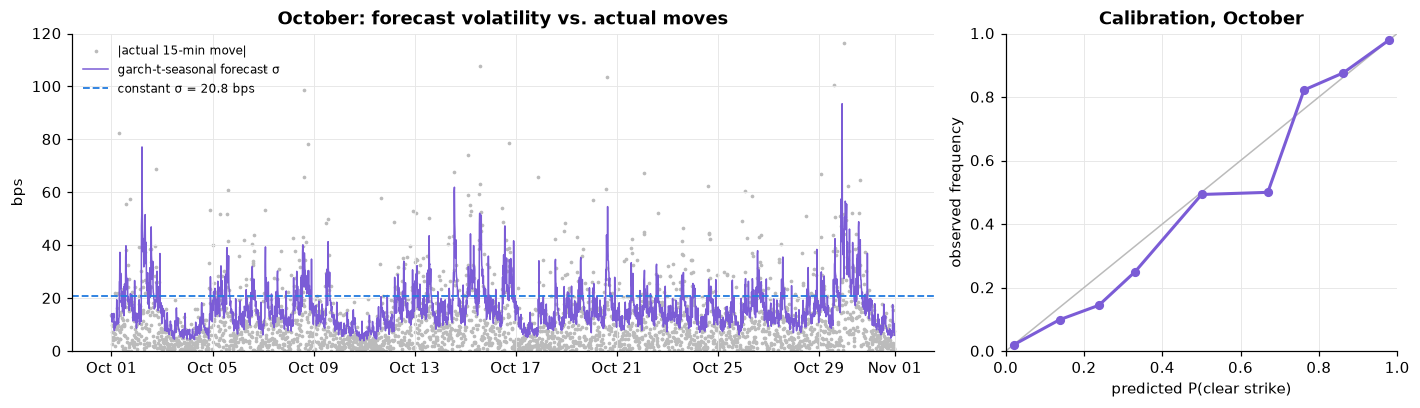

October moves divided by their forecast σ: sd 1.05 (1.00 if σ is right on average), excess kurtosis 16.5 (0 for normal shocks, 10.9 for the fitted t).

In [29]:
oc = W.loc[tem, ["t_decision", "r_bps"]].assign(sig=g_sig[tem])
oc["time"] = utc(oc.t_decision)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
ax.scatter(oc.time, oc.r_bps.abs(), s=2, color="#bbb", label="|actual 15-min move|")
ax.plot(oc.time, oc.sig, color=COLORS["garch"], lw=1, label=f"{best_vol} forecast σ")
ax.axhline(const_sd, color=COLORS["normal"], lw=1.2, ls="--", label=f"constant σ = {const_sd:.1f} bps")
import matplotlib.dates as mdates
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set(ylim=(0, 120), ylabel="bps", title="October: forecast volatility vs. actual moves"); ax.legend(frameon=False, loc="upper left", fontsize=8)
ax = axes[1]
rel = reliability(TE["garch"], TE.y)
ax.plot([0, 1], [0, 1], color="#bbb", lw=1)
ax.plot(rel.mean_pred, rel.obs_freq, marker="o", ms=5, color=COLORS["garch"])
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="predicted P(clear strike)", ylabel="observed frequency", title="Calibration, October")
plt.tight_layout(); plt.show()
z = (oc.r_bps - gm.mu) / oc.sig
show(f"October moves divided by their forecast σ: sd {z.std():.2f} (1.00 if σ is right on average), "
     f"excess kurtosis {stats.kurtosis(z):.1f} (0 for normal shocks, {6 / (gm.params['nu'] - 4):.1f} for the fitted t).")

**What October says.**
- **The September pick, GARCH(1,1) with Student-t shocks and the time-of-day adjustment, has the best October log loss of any model in the notebook** (0.2302, versus 0.2482 for the bell curve, about 7% better). It does this with 4 parameters plus the 96 time-of-day scales.
- **It beats the PyTorch net on log loss**, with the whole 95% range below zero. On Brier score the two are a statistical tie. Against the logistic regression it's a tie on both scores.
- **Plain GARCH with normal shocks, priced with Black-Scholes $N(d_2)$, is clearly better than the constant-σ bell curve but worse than the t version.** That puts numbers on the two separate problems with the textbook model: volatility isn't constant, and even after you fix that, the shocks aren't normal.
- **Even after dividing each October move by its forecast σ, the result still has excess kurtosis of about 16.** The shocks themselves are fat-tailed, which is why the Student-t versions keep winning. Volatility clustering is only part of the story.

So for this problem, a standard econometric volatility model does at least as well as the neural net, and every parameter in it has a meaning you can check (how fast shocks fade, how fat the tails are, how much the US open matters).

## 7. Comparing against Kalshi

Now for the real thing. Kalshi's KXBTC15M markets ask "will BTC be up in the next 15 minutes?", and the price of "yes" is basically the crowd's probability. I check whether my models' probabilities were closer to the actual outcomes than the market's, on the same markets at the same moment.

**The contract.** Series `KXBTC15M`, "BTC price up in next 15 mins?". The terms below come from Kalshi's public API (`btc_tails/kalshi.py`).

In [30]:
meta = json.loads((RAW_KALSHI / "_series_meta.json").read_text())
files = sorted(p for p in RAW_KALSHI.glob("KXBTC15M-*.json"))
recs = [json.loads(p.read_text()) for p in files]
sample = next(x for x in recs if x["market"])["market"]
ser = meta["series"]["series"]
terms = pd.DataFrame({"field": ["series", "sample ticker", "window", "strike (floor_strike)", "YES condition (rules_primary)", "strike_type",
                                "settlement source", "settlement value", "fee_type / fee_multiplier (series metadata, retrieved)",
                                "series fee-change history (show_historical=true)", "historical archive cutoff (market_settled_ts)"],
  "value": [ser["ticker"], sample["ticker"], f"{sample['open_time']} → {sample['close_time']}", sample["floor_strike"], sample["rules_primary"],
            sample["strike_type"], ser["settlement_sources"][0]["name"] + " BRTI", "simple average of 60 one-second BRTI values before close (rules_secondary)",
            f"{ser['fee_type']} / {ser['fee_multiplier']} (as of {meta['retrieved_utc']})", str(meta["fee_changes"]["series_fee_change_arr"]),
            meta["historical_cutoff"]["market_settled_ts"]]})
with pd.option_context("display.max_colwidth", 200): display(terms)

,field,value
0,series,KXBTC15M
1,sample ticker,KXBTC15M-26OCT010000-00
2,window,2026-10-01T03:45:00Z → 2026-10-01T04:00:00Z
3,strike (floor_strike),83663.77
4,YES condition (rules_primary),"If the simple average of the sixty seconds of CF Benchmarks' BRTI before 12:00 AM EDT on Oct 1, 2026 is at least the simple average of the sixty seconds of CF Benchmarks' BRTI before 11:45 PM EDT ..."
5,strike_type,greater_or_equal
6,settlement source,CF Benchmarks BRTI
7,settlement value,simple average of 60 one-second BRTI values before close (rules_secondary)
8,"fee_type / fee_multiplier (series metadata, retrieved)",quadratic / 1 (as of 2026-11-26T17:34:14+00:00)
9,series fee-change history (show_historical=true),[]


**What that means for a fair comparison**
- **The strike is set just before the window opens.** It's the average price over the 60 seconds before the open. So "yes" means "the closing average is at least the opening average". That's effectively a 0 bp strike, and it uses "at least" (≥) instead of the strict ">" from earlier.
- **Kalshi settles on a different price.** It uses BRTI, a US-dollar Bitcoin index built from several exchanges and averaged over a minute, not Binance's BTCUSDT price. Below I check how often Binance gives the same answer.
- **Everyone decides one minute in.** Kalshi quotes only exist once the window has opened. The first quote snapshot is at open + 1 min, so that's the decision time for both the market and my models, with 14 minutes left. Pretending to use it at the open would be peeking.
- **What the public data has:** each market's details (strike, result, volume) and 1-minute snapshots of the best "yes" bid, best "yes" ask and trade price. **What it doesn't have:** how many contracts were available at those prices, order book history, or actual fills. The fee schedule PDF linked from the API (`kalshi.com/docs/kalshi-fee-schedule.pdf`) blocked automated requests (HTTP 429), so I couldn't confirm what fees applied in October.

In [31]:
rows = []
for x in recs:
    m = x["market"]; T = x["window_open_utc"]
    row = {"t_decision_open": T, "ticker": m["ticker"] if m else None, "found": m is not None, "source": x["source"]}
    if m:
        row.update(floor_strike=m.get("floor_strike"), result=m.get("result"), volume=float(m.get("volume_fp") or m.get("volume") or 0))
        c = next((c for c in x["candlesticks"] if c["end_period_ts"] == T + 60), None)
        if c:
            g = lambda d, k: float(d.get(k + "_dollars", d.get(k)) or np.nan)
            row.update(quote_ts=c["end_period_ts"], bid=g(c["yes_bid"], "close"), ask=g(c["yes_ask"], "close"),
                       minute_volume=float(c.get("volume_fp", c.get("volume")) or 0))
    rows.append(row)
K = pd.DataFrame(rows)
K["has_quote"] = K.bid.gt(0) & K.ask.lt(1) & K.ask.gt(K.bid)
K["mid"] = (K.bid + K.ask) / 2
K["spread"] = K.ask - K.bid

# Binance proxies (minute candles): S at open+1min, opening/closing 60-second averages approximated by the mean of OHLC
mins = load_minutes(con).set_index("ts_open")
typ = mins[["open", "high", "low", "close"]].mean(axis=1)
K["S_dec"] = mins["close"].reindex(K.t_decision_open).to_numpy()            # candle T closes at T+60
K["K_proxy"] = typ.reindex(K.t_decision_open - 60).to_numpy()               # minute before the open
K["end_proxy"] = typ.reindex(K.t_decision_open + 840).to_numpy()            # last minute of the window
K["m"] = np.log(K.K_proxy / K.S_dec)
K["y"] = (K.result == "yes").astype(float)
K["basis_bps"] = np.log(K.floor_strike / K.K_proxy) * BPS
in_test = K.t_decision_open.between(TEST_START, T_MAX - 1)
cov = pd.Series({"15-min windows in test month": int(in_test.sum()), "market found": int((in_test & K.found).sum()),
                 "settled yes/no": int((in_test & K.result.isin(["yes", "no"])).sum()),
                 "quote candle ending at open+1min": int((in_test & K.quote_ts.notna()).sum()),
                 "two-sided quote (0 < bid < ask < 1)": int((in_test & K.has_quote).sum()),
                 "Binance proxies available": int((in_test & K[["S_dec", "K_proxy", "end_proxy"]].notna().all(axis=1)).sum())})
miss_et = utc(K.loc[in_test & ~K.found, "t_decision_open"]).dt.tz_convert("America/New_York")
display(cov.to_frame("count"))
show(f"*{len(miss_et)} windows have no market. Their opens (ET) fall on weekdays {sorted(set(miss_et.dt.day_name()))} between "
     f"{miss_et.dt.strftime('%H:%M').min()} and {miss_et.dt.strftime('%H:%M').max()}, which matches Kalshi's documented scheduled maintenance "
     f"(every Thursday 3:00–5:00 AM ET, docs.kalshi.com/getting_started/maintenance_and_pauses).*")

,count
15-min windows in test month,2976
market found,2936
settled yes/no,2936
quote candle ending at open+1min,2936
two-sided quote (0 < bid < ask < 1),2936
Binance proxies available,2976


*40 windows have no market. Their opens (ET) fall on weekdays ['Thursday'] between 03:00 and 04:45, which matches Kalshi's documented scheduled maintenance (every Thursday 3:00–5:00 AM ET, docs.kalshi.com/getting_started/maintenance_and_pauses).*

In [32]:
KE = K[in_test & K.has_quote & K.result.isin(["yes", "no"]) & K[["S_dec", "K_proxy", "end_proxy"]].notna().all(axis=1)].copy()
KE["proxy_yes"] = (KE.end_proxy >= KE.K_proxy).astype(float)
agree = (KE.proxy_yes == KE.y).mean()
show(f"**Proxy check.** Binance (mean of OHLC in the minute before the open vs the last minute) reproduces the Kalshi outcome in "
     f"{agree:.1%} of {len(KE):,} markets. Strike vs Binance proxy basis: median {KE.basis_bps.median():+.2f} bps, "
     f"5–95% range [{KE.basis_bps.quantile(.05):+.2f}, {KE.basis_bps.quantile(.95):+.2f}] bps. To keep the USD/USDT basis out of the forecast, the "
     f"model's required move is measured Binance-to-Binance: m = log(K_proxy / S at open+1min).")
cols = ["ticker", "t_decision_open", "quote_ts", "floor_strike", "K_proxy", "S_dec", "bid", "ask", "mid", "result"]
KE = KE.sort_values("t_decision_open").reset_index(drop=True)
ex3 = KE[cols].iloc[[0, len(KE)//2, -1]].copy()
ex3["window open (UTC)"] = utc(ex3.pop("t_decision_open")); ex3["quote time (UTC)"] = utc(ex3.pop("quote_ts"))
ex3["quote age at decision"] = "0 s (end-of-minute snapshot)"
ex3

**Proxy check.** Binance (mean of OHLC in the minute before the open vs the last minute) reproduces the Kalshi outcome in 96.5% of 2,936 markets. Strike vs Binance proxy basis: median -11.66 bps, 5–95% range [-18.60, -0.96] bps. To keep the USD/USDT basis out of the forecast, the model's required move is measured Binance-to-Binance: m = log(K_proxy / S at open+1min).

,ticker,floor_strike,K_proxy,S_dec,bid,ask,mid,result,window open (UTC),quote time (UTC),quote age at decision
0,KXBTC15M-26SEP302015-15,83569.02,83614.1075,83578.01,0.39,0.40,0.395,no,2026-10-01 00:00:00+00:00,2026-10-01 00:01:00+00:00,0 s (end-of-minute snapshot)
1468,KXBTC15M-26OCT160915-15,81943.09,82047.1250,82052.49,0.50,0.51,0.505,no,2026-10-16 13:00:00+00:00,2026-10-16 13:01:00+00:00,0 s (end-of-minute snapshot)
2935,KXBTC15M-26OCT312000-00,77385.45,77519.5850,77523.86,0.54,0.55,0.545,yes,2026-10-31 23:45:00+00:00,2026-10-31 23:46:00+00:00,0 s (end-of-minute snapshot)


**Re-fitting the models for Kalshi's timing.** Kalshi's question is slightly different from the one in sections 4 and 5. It's a 14-minute move, from the price at open + 1 min to the average price in the last minute. So I refit the bell curve and the count model on that exact Binance quantity, $y = \log(\text{average price in minute } T{+}14\,/\,\text{close of minute } T)$. I use the training months only, and "≥" to match the contract. For the neural network I reuse the trained model and shrink its width by the training ratio $\text{sd}(y)/\text{sd}(r)$. I do the same for the GARCH model's σ. That's a shortcut, not a separately trained model.

**Who was closer: the market or my models?** The GARCH column is the September pick from section 6. Every row uses the same 2,936 markets, scored against Kalshi's actual result. In the last table, a positive difference means the model did worse than the market.

In [33]:
win = df[["t_decision", "split"]].copy()
win["y_h"] = (np.log(typ.reindex(win.t_decision + 840).to_numpy()) - np.log(mins["close"].reindex(win.t_decision).to_numpy())) * BPS
ytr = win.loc[win.split == "train", "y_h"].dropna().to_numpy()
mu_h, sd_h = ytr.mean(), ytr.std(ddof=1)
ratio = sd_h / (normal.sigma * BPS)
KE["normal"] = stats.norm.sf((KE.m * BPS - mu_h) / sd_h)
ys = np.sort(ytr); KE["empirical"] = 1 - np.searchsorted(ys, KE.m.to_numpy() * BPS, side="left") / len(ys)   # P(y >= m)
KE = KE.merge(W[["t_decision", "mu_t", "sig_t"]], left_on="t_decision_open", right_on="t_decision", how="left")
KE["torch"] = stats.norm.sf((KE.m * BPS - KE.mu_t * ratio) / (KE.sig_t * ratio))
KE = KE.merge(G, left_on="t_decision_open", right_on="t_decision", how="left", suffixes=("", "_g"))
KE["garch"] = gm.prob_above(KE.m * BPS, KE.sig_g * ratio)
KE["market"] = KE["mid"]
KE["day"] = utc(KE.t_decision_open).dt.date
KM = ["market", "normal", "empirical", "torch", "garch"]
ksc = score_table(KE.dropna(subset=KM), KM).set_index("model")[["n", "brier", "log_loss"]]
kd = []
for mdl in ["normal", "empirical", "torch", "garch"]:
    for metric in ["log_loss", "brier"]:
        est, l, h = block_bootstrap_diff(KE.dropna(subset=KM), mdl, "market", metric)
        kd.append({"comparison": f"{mdl} − market", "metric": metric, "difference": est, "95% CI low": l, "95% CI high": h})
show(f"Same {len(KE):,} October markets for every row; outcome = actual Kalshi result. Median quoted spread at open+1 min: "
     f"{KE.spread.median():.3f} $; median trade volume in that minute: {KE.minute_volume.median():,.0f} contracts.")
display(ksc.round(5)); pd.DataFrame(kd).round(5)

Same 2,936 October markets for every row; outcome = actual Kalshi result. Median quoted spread at open+1 min: 0.010 $; median trade volume in that minute: 171,810 contracts.

,n,brier,log_loss
model,,,
market,2936,0.23288,0.65719
normal,2936,0.23708,0.66705
empirical,2936,0.23741,0.66896
torch,2936,0.23512,0.66258
garch,2936,0.23674,0.66650


,comparison,metric,difference,95% CI low,95% CI high
0,normal − market,log_loss,0.00986,0.00491,0.01488
1,normal − market,brier,0.00420,0.00185,0.00661
2,empirical − market,log_loss,0.01177,0.00634,0.01686
3,empirical − market,brier,0.00453,0.00217,0.00667
4,torch − market,log_loss,0.00539,0.00155,0.00953
5,torch − market,brier,0.00224,0.00065,0.00383
6,garch − market,log_loss,0.00931,0.00493,0.01357
7,garch − market,brier,0.00386,0.00218,0.00555


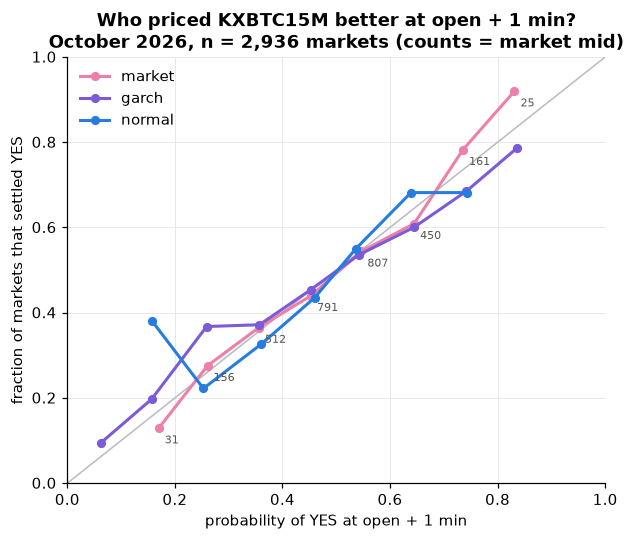

*Bins of width 0.1; bins with fewer than 20 markets are not drawn for any line.*

In [34]:
fig, ax = plt.subplots(figsize=(5.8, 5))
ax.plot([0, 1], [0, 1], color="#bbb", lw=1)
MIN_BIN = 20
for m in ["market", "garch", "normal"]:
    rel = reliability(KE[m], KE.y); rel = rel[rel.n >= MIN_BIN]
    ax.plot(rel.mean_pred, rel.obs_freq, marker="o", ms=5, color=COLORS[m], label=m)
rel = reliability(KE["market"], KE.y); rel = rel[rel.n >= MIN_BIN]
for _, rr in rel.iterrows():
    ax.annotate(f"{rr.n}", (rr.mean_pred, rr.obs_freq), textcoords="offset points", xytext=(4, -10), fontsize=7, color="#555")
ax.set(xlabel="probability of YES at open + 1 min", ylabel="fraction of markets that settled YES", xlim=(0, 1), ylim=(0, 1),
       title=f"Who priced KXBTC15M better at open + 1 min?\nOctober 2026, n = {len(KE):,} markets (counts = market mid)")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()
show(f"*Bins of width 0.1; bins with fewer than {MIN_BIN} markets are not drawn for any line.*")

**What this can and can't show.** With this data I can compare accuracy: my models vs. the market vs. what actually happened, on the same markets, at a moment when both sides know the same things. I **can't** say whether you could have made money:
- the quote snapshots show the best bid and ask but not how many contracts were there, so I can't show that an order would have filled at those prices;
- I couldn't get the fee schedule that applied in October 2026 (the PDF returned HTTP 429, and the API only shows the *current* fee settings and an empty change history);
- I have no real trades, so I can't measure slippage, or whether my orders would mostly get filled exactly when I'm wrong.

So the profit numbers in section 8 assume every order fills at the quoted price, which flatters them. Testing **market making** (posting both buy and sell orders and earning the gap) would need even more: full order book history, my own order fills with timestamps, and what the price did after each fill. None of that is in these snapshots.

## 8. Trying to find a profitable strategy

Section 7 found the market more accurate than my models one minute into each window. That doesn't rule out making money, though. A strategy only needs to find the *occasional* bet where the price is wrong by more than the fee. So I tried four different strategies. Each one gets its rules picked using **September** only, and then it's tested once on **October**.

| | strategy | idea |
|---|---|---|
| S1 | **Model edge at the open** | Bet when the GARCH model from section 6 disagrees with the price one minute in by more than a threshold. |
| S2 | **Live fair value** | Every minute of the window, compute a fair probability from where Binance is relative to the strike, how much time is left, and how jumpy the last hour was. Bet when the Kalshi price lags behind. |
| S3 | **Mispriced price ranges** | Look for price ranges where the market was systematically wrong in September (for example, contracts at 90¢ winning more than 90% of the time), and bet those in October. |
| S4 | **Regression on top of the market** | A logistic regression that combines the market price, S2's fair value, the last minute's Binance move, the spread, and time left. Bet when it disagrees with the price. |

**Rules for every strategy**
- I buy **1 contract** at the quoted price (the ask for "yes", 1 − bid for "no"), with at most one bet per market.
- **Fee:** $0.07 \times P \times (1-P)$ per contract. That's Kalshi's published formula with the multiplier the API reports for this series. *Not verified for October* (see section 7).
- **Fills are assumed.** The data doesn't show how many contracts were at each price, so every result here assumes my 1 contract would have filled. That's optimistic.
- **Rules are chosen on September.** The threshold, the minutes allowed, and the price ranges all come from September. If nothing made money in September, I'd simply not trade, and the table says so. October is the only honest test.
- **S1 used to run on model D.** Before I added the GARCH section, S1 used the neural net's probabilities and lost 4.6¢ per bet in October. I switched it to the GARCH model because GARCH won on September. The threshold is still picked on September only.
- **Delay test.** For the strategies that trade later in the window, I also rerun them filling at the *next* minute's price, as if I were a bit slow.

The full-window quotes come from `python -m btc_tails.kalshi 2026-09-01 2026-11-01 --full`, and the strategy code is in `btc_tails/strategies.py`.

,markets,market-minutes with a two-sided quote
month,,
Oct (test),2936,39867
Sep (rule-picking),2848,38961


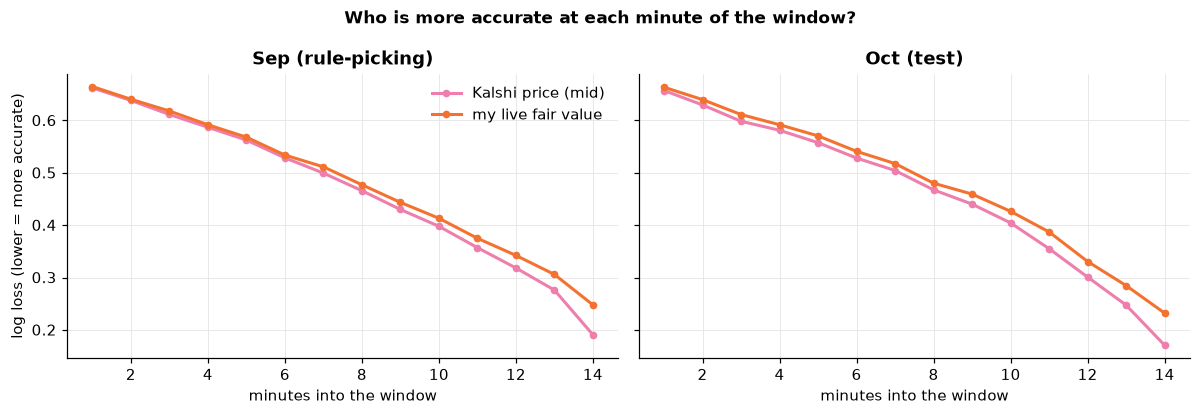

In [35]:
from btc_tails import RAW_KALSHI_FULL
from btc_tails.strategies import load_full_quotes, binance_state, FairValue, edge_signals, execute, summarize, fee
from sklearn.linear_model import LogisticRegression

minutes_df = mins.reset_index()
Q = load_full_quotes(RAW_KALSHI_FULL)
Q = pd.concat([Q.reset_index(drop=True), binance_state(minutes_df, Q["T"], Q.j)], axis=1).dropna(subset=["S_j", "K_proxy", "vol1m"])
Q = Q[Q["T"].between(VAL_START, T_MAX - 1)].reset_index(drop=True)
Q["month"] = np.where(Q["T"] >= TEST_START, "Oct (test)", "Sep (rule-picking)")
Q["dom"] = utc(Q["T"]).dt.day
fv = FairValue(minutes_df, df.loc[df.split == "train", "t_decision"].to_numpy())   # learned from May–Aug only
Q["p_fair"] = fv.prob(Q, Q.j.to_numpy())
display(Q.groupby("month").agg(markets=("ticker", "nunique"), **{"market-minutes with a two-sided quote": ("j", "size")}))

acc = (Q.groupby(["month", "j"]).apply(lambda g: pd.Series({"market": log_loss(g.mid, g.y), "fair value (S2)": log_loss(g.p_fair, g.y)}),
                                        include_groups=False).reset_index())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, mo in zip(axes, ["Sep (rule-picking)", "Oct (test)"]):
    g = acc[acc.month == mo]
    ax.plot(g.j, g["market"], marker="o", ms=4, color=COLORS["market"], label="Kalshi price (mid)")
    ax.plot(g.j, g["fair value (S2)"], marker="o", ms=4, color=COLORS["empirical"], label="my live fair value")
    ax.set(title=mo, xlabel="minutes into the window")
axes[0].set_ylabel("log loss (lower = more accurate)"); axes[0].legend(frameon=False)
fig.suptitle("Who is more accurate at each minute of the window?", fontweight="bold"); plt.tight_layout(); plt.show()

**Reading the chart.** Both lines drop as the window goes on, because the outcome gets easier to call. The question is whether my orange line ever drops below the pink market line. If it never does, any edge would have to come from a few specific moments rather than from being more accurate overall.

In [36]:
def pick(rows, grid, make_sig, delay, min_trades=30):
    # Best parameters on September by total P&L; None if nothing made money there.
    best = None
    for params in grid:
        s = summarize(execute(rows, make_sig(rows, *params), delay)); s["params"] = params
        if s["trades"] >= min_trades and (best is None or s["total ($)"] > best["total ($)"]):
            best = s
    return best

results, trade_log = [], {}
def record(name, sep_best, oct_rows, sig_fn, delays, rule):
    for dl in delays:
        tr = execute(oct_rows, sig_fn(oct_rows), dl)
        s = summarize(tr)
        label = name + (" (filled 1 min late)" if dl else "")
        results.append({"strategy": label, "rule picked on Sep": rule,
                        "Sep P&L ($)": round(sep_best["total ($)"], 2) if sep_best else None, **s})
        trade_log[label] = tr

# S1: the GARCH model's price at open + 1 minute (same probabilities as section 7)
Q1 = Q[Q.j == 1].merge(G[["t_decision", "sig_g"]], left_on="T", right_on="t_decision")
Q1["p_garch"] = gm.prob_above(np.log(Q1.K_proxy / Q1.S_j) * BPS, Q1.sig_g * ratio)
THETAS = [0, .01, .02, .03, .05, .08]
s1 = lambda d, t: edge_signals(d, "p_garch", t)
b1 = pick(Q1[Q1.month.str.startswith("Sep")], [(t,) for t in THETAS], s1, 0)
record("S1 model edge at the open", b1, Q1[Q1.month.str.startswith("Oct")], lambda d: s1(d, *b1["params"]), [0],
       f"edge > {b1['params'][0]*100:.0f}¢ after fees")

# S2: live fair value, minutes 1–13 (rules picked with the 1-minute delay, the more realistic case)
QL = Q[Q.j <= 13].reset_index(drop=True)
SEP, OCT = QL.month.str.startswith("Sep"), QL.month.str.startswith("Oct")
def s2(d, t, jmin):
    s = edge_signals(d, "p_fair", t); s[d.j.to_numpy() < jmin] = 0; return s
b2 = pick(QL[SEP], [(t, jm) for t in THETAS + [.1] for jm in (1, 4, 7, 10, 12)], s2, 1)
record("S2 live fair value", b2, QL[OCT], lambda d: s2(d, *b2["params"]), [0, 1],
       f"edge > {b2['params'][0]*100:.0f}¢ after fees, from minute {b2['params'][1]}")

# S3: price ranges that were mispriced in September (5¢ buckets × minute × side; needs ≥100 Sep markets and t > 2)
QL["bucket"] = np.floor(QL.mid * 20) / 20
cells = []
for (j, bk), g in QL[SEP].groupby(["j", "bucket"]):
    for side, pnl in ((1, g.y - g.ask - fee(g.ask)), (-1, g.bid - g.y - fee(g.bid))):
        if len(g) >= 100 and pnl.mean() > 0 and pnl.mean() / (pnl.std(ddof=1) / np.sqrt(len(g))) > 2:
            cells.append({"minute": j, "price range": f"{bk:.2f}–{bk + .05:.2f}", "bet": "yes" if side == 1 else "no",
                          "Sep markets": len(g), "Sep avg P&L (¢)": round(100 * pnl.mean(), 2), "_key": (j, bk), "_side": side})
cell_map = {c["_key"]: c["_side"] for c in cells}
s3 = lambda d: np.array([cell_map.get((j, b), 0) for j, b in zip(d.j, d.bucket)])
sep3 = execute(QL[SEP], s3(QL[SEP]))
record("S3 mispriced price ranges", {"total ($)": sep3.pnl.sum()}, QL[OCT], s3, [0, 1], f"{len(cells)} (minute, price range) cells")

# S4: logistic regression on top of the market. Fit on Sep 1–20, threshold picked on Sep 21–30.
lg = lambda p: np.log(np.clip(p, 1e-3, 1 - 1e-3) / (1 - np.clip(p, 1e-3, 1 - 1e-3)))
X4 = lambda d: np.column_stack([lg(d.mid), lg(d.p_fair), d.j / 14, d.ret1m / d.vol1m, d.spread * 100])
fit4 = QL[SEP & (QL.dom <= 20)]
reg = LogisticRegression(C=1.0, max_iter=2000).fit(X4(fit4), fit4.y)
QL["p_stack"] = reg.predict_proba(X4(QL))[:, 1]
s4 = lambda d, t: edge_signals(d, "p_stack", t)
b4 = pick(QL[SEP & (QL.dom > 20)], [(t,) for t in THETAS], s4, 1)
record("S4 regression on top of the market", b4, QL[OCT], lambda d: s4(d, *b4["params"]), [0, 1],
       f"edge > {b4['params'][0]*100:.0f}¢ after fees")

R = pd.DataFrame(results)
R["made money on Sep?"] = R["Sep P&L ($)"].map(lambda v: "yes" if v and v > 0 else "no → would not trade")
show("**October results, 1 contract per bet.** P&L is per contract in cents; the 95% range resamples whole October days.")
display(R[["strategy", "rule picked on Sep", "Sep P&L ($)", "made money on Sep?", "trades", "win rate", "avg before fees (¢)",
           "avg P&L (¢)", "total ($)", "95% CI low (¢)", "95% CI high (¢)"]].round(3))
show("S4 regression weights (inputs: market log-odds, fair-value log-odds, time elapsed, last-minute move ÷ volatility, spread in ¢): "
     + ", ".join(f"{w:+.3f}" for w in reg.coef_[0]))
show("**S3's September cells:**"); display(pd.DataFrame(cells).drop(columns=["_key", "_side"]))

**October results, 1 contract per bet.** P&L is per contract in cents; the 95% range resamples whole October days.

,strategy,rule picked on Sep,Sep P&L ($),made money on Sep?,trades,win rate,avg before fees (¢),avg P&L (¢),total ($),95% CI low (¢),95% CI high (¢)
0,S1 model edge at the open,edge > 8¢ after fees,8.42,yes,220,0.545,-3.455,-4.972,-10.938,-9.701,0.404
1,S2 live fair value,"edge > 5¢ after fees, from minute 1",11.64,yes,2095,0.547,-1.114,-2.537,-53.160,-4.617,-0.569
2,S2 live fair value (filled 1 min late),"edge > 5¢ after fees, from minute 1",11.64,yes,2036,0.551,-0.599,-1.938,-39.449,-3.871,-0.093
3,S3 mispriced price ranges,"6 (minute, price range) cells",30.60,yes,719,0.853,-0.520,-1.242,-8.928,-3.068,0.713
4,S3 mispriced price ranges (filled 1 min late),"6 (minute, price range) cells",30.60,yes,719,0.853,0.061,-0.616,-4.427,-2.398,1.283
5,S4 regression on top of the market,edge > 3¢ after fees,-9.26,no → would not trade,432,0.495,-2.758,-4.233,-18.288,-9.308,0.676
6,S4 regression on top of the market (filled 1 m...,edge > 3¢ after fees,-9.26,no → would not trade,360,0.508,-2.797,-4.169,-15.007,-10.100,1.323


S4 regression weights (inputs: market log-odds, fair-value log-odds, time elapsed, last-minute move ÷ volatility, spread in ¢): +0.702, +0.250, -0.067, +0.015, -0.053

**S3's September cells:**

,minute,price range,bet,Sep markets,Sep avg P&L (¢)
0,6,0.90–0.95,yes,113,6.09
1,7,0.80–0.85,yes,155,5.06
2,8,0.90–0.95,yes,177,3.94
3,8,0.95–1.00,yes,139,2.21
4,9,0.45–0.50,no,102,9.94
5,9,0.90–0.95,yes,237,3.06


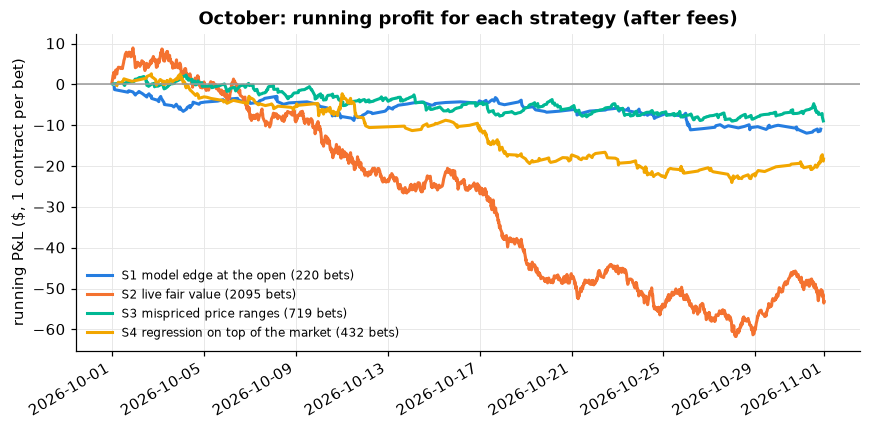

In [37]:
fig, ax = plt.subplots(figsize=(8, 4))
palette = ["#257de0", "#f47230", "#00b894", "#f2a600"]
main = [k for k in trade_log if "late" not in k]
for c, k in zip(palette, main):
    tr = trade_log[k].sort_values(["T", "j"])
    ax.plot(utc(tr["T"]), tr.pnl.cumsum(), color=c, label=f"{k} ({len(tr)} bets)")
ax.axhline(0, color="#999", lw=1)
ax.set(ylabel="running P&L ($, 1 contract per bet)", title="October: running profit for each strategy (after fees)")
ax.legend(frameon=False, fontsize=8); fig.autofmt_xdate(); plt.tight_layout(); plt.show()

**What the tables show.** Each row reports how many bets a strategy made in October, how often it won, and its average result per contract before and after fees. The 95% range shows how much that average could move from luck alone. A strategy has really found something only if the whole range sits above zero. The running-profit chart shows whether any gains were steady or came from a few lucky days.

## 9. Summary

- **BTC's 15-minute returns are far from normal.** A typical move is about 20 bps. Moves past ±25 bps were rarer than a normal distribution predicts (2,295 vs about 3,682), and moves past ±50 bps were more than twice as common (466 vs about 210). Excess kurtosis is about 17.
- **There's no reliable skew.** Skewness ranged from −0.41 (October) to +1.54 (August) and mostly goes away without the 5 biggest moves.
- **Volatility clustering, intraday seasonality, and fat-tailed shocks all matter.** October log loss: normal 0.2482, empirical 0.2399, neural net 0.2335, logistic 0.2327, GARCH-normal 0.2359, **GARCH-t with the time-of-day adjustment 0.2302** (best, about 7% better than normal).
- **GARCH persistence runs into the unit-root boundary** (α+β ≈ 1), so volatility shocks barely fade at this horizon and EWMA is almost as good. The fitted Student-t has ν ≈ 4.5.
- **Kalshi's prices beat every model.** One minute into the window, the market's log loss was 0.6572. The best model there was the neural net at 0.6626, and GARCH-t was 0.6665. Every gap is bigger than chance would explain.
- **None of the four strategies made money in October** after fees, with rules picked on September (S1 −5.0¢, S2 −2.5¢, S3 −1.2¢, S4 −4.2¢ per contract). These numbers assume fills at the quoted price, which is optimistic. The market already prices BTC's volatility well. An edge would probably need order-book data or faster prices than these 1-minute snapshots.